# DSB102 Group Project — Sydney Bank
## Task 1: Exploratory Data Analysis

**Purpose:** Understand customer churn patterns before modelling. Compare customers who churned (`Churn = 1`) with customers who were retained (`Churn = 0`).

This is a working EDA notebook. Explore broadly first, then keep the strongest findings for the final report.

## 1. Import libraries
Import the packages needed for data manipulation and visualisation.

In [1]:
# Import libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import statsmodels.api as sm
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
from scipy.stats import gaussian_kde
from sklearn.metrics import mutual_info_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

## 2. Load data
Load the original Sydney Bank customer churn dataset.

Check:
- number of observations and variables
- column names
- first few observations

In [2]:
# Load the dataset
df = pd.read_csv('sydney_bank_customer_churn_raw.csv')

# Check load
df.head(5)

,CustomerID,Age,Gender,TenureMonths,NumProducts,IsActiveMember,Balance,NumTransactions_Last6Months,ComplaintsLast6Months,Churn
0,C58090,74,female,105,1,Yes,26860.99,7,1,0
1,C16926,26,female,46,1,Yes,28801.87,5,2,0
2,C15856,36,F,81,2,No,15813.65,15,0,0
3,C36044,53,male,86,1,Yes,91533.81,10,0,0
4,C36810,69,male,117,2,No,72984.53,11,2,0


## 3. Understand the variables
Inspect data types and variable contents.

Identify:
- target variable
- numerical predictors
- categorical predictors
- identifier / non-predictive columns

In [3]:
# Inspect columns, data types and example values

# Dataset Shape and Data Types
print("--- Dataset Info ---")
df.info()

# Summary Statistics for Numerical Columns
print("\n--- Numerical Summary ---")
# Transpose (.T) for easier reading of statistical measures
print(df.describe().round(2).T)

print("\n--- Products & Activity ---")
print("NumProducts:\n", df['NumProducts'].value_counts())
print("\nIsActiveMember:\n", df['IsActiveMember'].value_counts())

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   1600 non-null   object 
 1   Age                          1600 non-null   int64  
 2   Gender                       1600 non-null   object 
 3   TenureMonths                 1600 non-null   int64  
 4   NumProducts                  1600 non-null   int64  
 5   IsActiveMember               1600 non-null   object 
 6   Balance                      1600 non-null   float64
 7   NumTransactions_Last6Months  1600 non-null   int64  
 8   ComplaintsLast6Months        1600 non-null   int64  
 9   Churn                        1600 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 125.1+ KB

--- Numerical Summary ---
                              count      mean       std   min       25%  \
Age       

## 4. Data quality checks
Check for:
- missing values
- duplicate observations
- inconsistent categorical values
- unusual or potentially invalid values

**Important:** Investigate the known formatting inconsistency in `Gender`. Do not automatically assume unusual values are errors.

In [4]:
# Perform data quality checks

# Missing Values Check
print("\n--- Missing Values ---")
print(df.isnull().sum())

# Categorical Distributions (Identify inconsistencies)
print("\n--- Gender Value Counts ---")
print(df['Gender'].value_counts(dropna=False))


--- Missing Values ---
CustomerID                     0
Age                            0
Gender                         0
TenureMonths                   0
NumProducts                    0
IsActiveMember                 0
Balance                        0
NumTransactions_Last6Months    0
ComplaintsLast6Months          0
Churn                          0
dtype: int64

--- Gender Value Counts ---
Gender
female    284
male      272
Female    272
M         265
Male      257
F         250
Name: count, dtype: int64


## 5. Data cleaning
Standardise inconsistent categorical values identified above.

Record every cleaning decision so it can be explained and reproduced later.

In [5]:
# Apply agreed cleaning steps
# Clean and Encode Categorical Variables

# Standardise Gender and convert to binary (Female = 1, Male = 0)
df['Gender'] = df['Gender'].str.upper().str.strip()
df['Is_Female'] = df['Gender'].replace({'MALE': 0, 'M': 0, 'FEMALE': 1, 'F': 1})

# Convert Active Member status to binary (Yes = 1, No = 0)
df['IsActiveMember_Flag'] = df['IsActiveMember'].map({'Yes': 1, 'No': 0})

# Drop the original text columns and CustomerID (which has no predictive value)
df_clean = df.drop(columns=['CustomerID', 'Gender', 'IsActiveMember'])

# Save to CSV
df_clean.to_csv('sydney_bank_customer_churn_cleaned.csv', index=False)

In [6]:
# Check cleaned data
df_clean.head(5)

,Age,TenureMonths,NumProducts,Balance,NumTransactions_Last6Months,ComplaintsLast6Months,Churn,Is_Female,IsActiveMember_Flag
0,74,105,1,26860.99,7,1,0,1,1
1,26,46,1,28801.87,5,2,0,1,1
2,36,81,2,15813.65,15,0,0,1,0
3,53,86,1,91533.81,10,0,0,0,1
4,69,117,2,72984.53,11,2,0,0,0


## 6. Overall churn landscape
Investigate the target variable `Churn`.

Determine:
- number of retained customers
- number of churned customers
- percentage retained
- percentage churned

Create a simple visualisation if useful.

In [7]:
# Summarise overall churn
# Target Variable Distribution (Churn)
print("\n--- Churn Distribution (count) ---")
print(df['Churn'].value_counts())

print("\n--- Churn Distribution (%) ---")
print(df['Churn'].value_counts(normalize=True).round(4) * 100)


--- Churn Distribution (count) ---
Churn
0    1303
1     297
Name: count, dtype: int64

--- Churn Distribution (%) ---
Churn
0    81.44
1    18.56
Name: proportion, dtype: float64


## 7. Churned vs retained — numerical variables
Compare numerical characteristics between retained (`Churn = 0`) and churned (`Churn = 1`) customers.

Possible variables to investigate include:
- `Age`
- `TenureMonths`
- `NumProducts`
- `Balance`
- `NumTransactions_Last6Months`
- `ComplaintsLast6Months`

Do not select the final three comparisons yet. Explore first and identify which differences are meaningful.

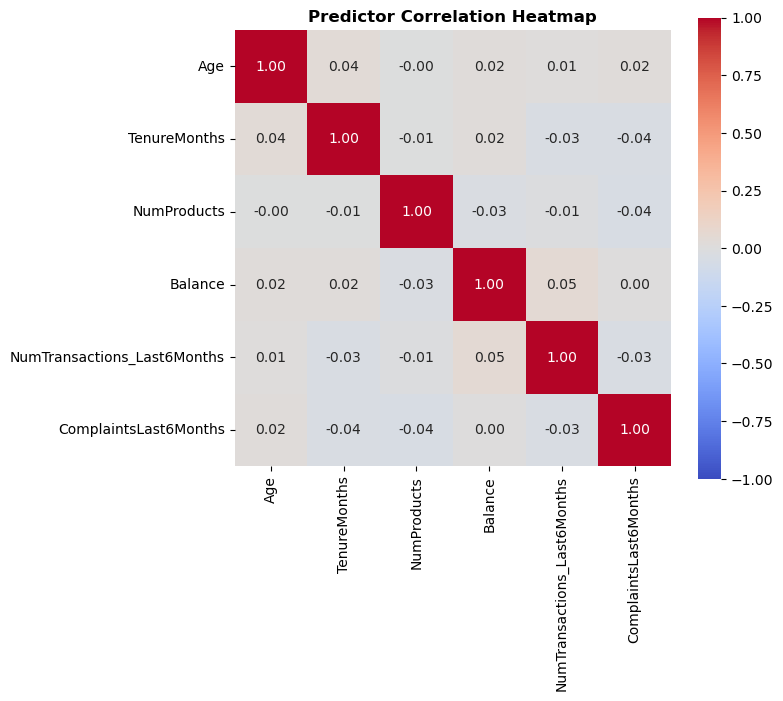

In [8]:
# Compare numerical variables by churn status

# Check predictors for collinearity (correlation)
# Calculate the Pearson correlation matrix
columns_cat = ['Is_Female', 'IsActiveMember_Flag', 'Churn']
corr_matrix = df_clean.drop(columns=columns_cat, inplace=False).corr()

# Plot the correlation matrick heatmap
plt.figure(figsize=(8, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", 
            vmin=-1, vmax=1, square=True)
plt.title('Predictor Correlation Heatmap', fontweight='bold')
plt.tight_layout()
# Save the plot as a high-resolution PNG
plt.savefig('Figures\correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

In [9]:
# Test continous predictors relationship to churn with Logistic Regression
# Separate predictors (X) and target (y)
X = df_clean.drop(columns=columns_cat, inplace=False)
y = df_clean['Churn']

# Add a constant (intercept) manually
X = sm.add_constant(X)

# Fit the Logit model
model = sm.Logit(y, X)
results = model.fit()

# Print the statistical summary table
print(results.summary())

Optimization terminated successfully.
         Current function value: 0.417396
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 1600
Model:                          Logit   Df Residuals:                     1593
Method:                           MLE   Df Model:                            6
Date:                Mon, 05 Oct 2026   Pseudo R-squ.:                  0.1301
Time:                        19:26:52   Log-Likelihood:                -667.83
converged:                       True   LL-Null:                       -767.71
Covariance Type:            nonrobust   LLR p-value:                 2.148e-40
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                           1.0090      0.351      2.873      0.004   

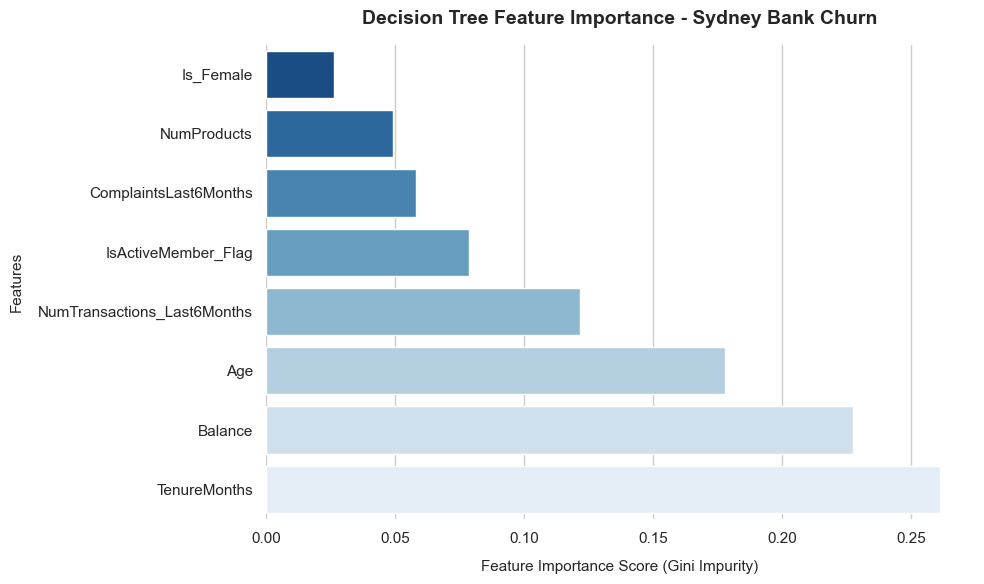

In [10]:
# Fit Decision tree to get churn predictors importance

# Set seaborn theme for clean executive styling
sns.set_theme(style="whitegrid", palette="Blues_r")

# Load dataset and prepare features
df = df_clean.copy()
X = df.drop(columns=['Churn'])
y = df['Churn']

# Fit classifier
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_classifier.fit(X, y)

# Extract and sort feature importances
importance_df = pd.DataFrame({
    'Feature': X.columns, 
    'Importance': dt_classifier.feature_importances_
}).sort_values(by='Importance', ascending=True)

# Generate the plot using seaborn
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df, 
    x='Importance', 
    y='Feature', 
    palette='Blues_r' # Applies a dark-to-light gradient
)

# Format titles and remove chart borders
plt.title('Decision Tree Feature Importance - Sydney Bank Churn', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Feature Importance Score (Gini Impurity)', fontsize=11, labelpad=10)
plt.ylabel('Features', fontsize=11, labelpad=10)
sns.despine(left=True, bottom=True) # Removes top, right, bottom, and left borders

# Render
plt.tight_layout()
# Save the plot as a high-resolution PNG
plt.savefig('Figures\DecisionTreeFeatureImportance.png', dpi=300, bbox_inches='tight')
plt.show()

In [11]:
df_clean.head(2)

,Age,TenureMonths,NumProducts,Balance,NumTransactions_Last6Months,ComplaintsLast6Months,Churn,Is_Female,IsActiveMember_Flag
0,74,105,1,26860.99,7,1,0,1,1
1,26,46,1,28801.87,5,2,0,1,1


In [12]:
# Calculate the exact mean for retained (0) vs churned (1) for important continuous features (Decision Tree)
comparison = df_clean.groupby('Churn')[['Age', 'TenureMonths', 'Balance', 'NumTransactions_Last6Months', 'NumProducts']].mean()
print(comparison.round(2))

         Age  TenureMonths   Balance  NumTransactions_Last6Months  NumProducts
Churn                                                                         
0      48.61         66.18  47084.07                         8.19         1.78
1      50.14         39.49  38254.03                         7.60         1.67


In [13]:
# Calculate the median for retained (0) vs churned (1) for important continuous features (Decision Tree)
comparison = df_clean.groupby('Churn')[['Age', 'TenureMonths', 'Balance', 'NumTransactions_Last6Months', 'NumProducts']].median()
print(comparison.round(2))

        Age  TenureMonths   Balance  NumTransactions_Last6Months  NumProducts
Churn                                                                        
0      48.0          70.0  40180.22                          8.0          2.0
1      52.0          32.0  31814.64                          7.0          1.0


**PCA: 2-Dimensional Plot**

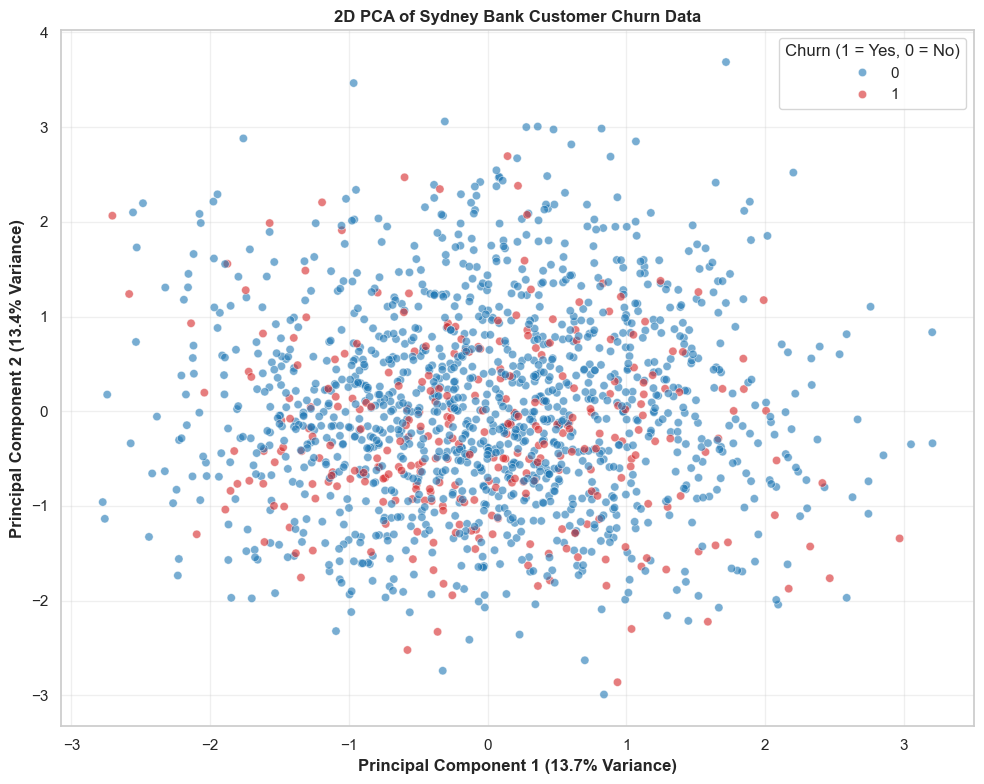

In [14]:
# Separate features and target
X = df_clean.drop('Churn', axis=1)
y = df_clean['Churn']

# Standardise the features 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA to reduce to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame for plotting
pca_df = pd.DataFrame(data=X_pca, columns=['Principal Component 1', 'Principal Component 2'])
pca_df['Churn'] = y

# Plot the PCA
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='Principal Component 1', 
    y='Principal Component 2',
    hue='Churn',
    palette=['#1f77b4', '#d62728'],
    data=pca_df,
    alpha=0.6
)

# Dynamically extract the explained variance for the axes
var_1 = pca.explained_variance_ratio_[0]
var_2 = pca.explained_variance_ratio_[1]

plt.title('2D PCA of Sydney Bank Customer Churn Data', fontweight='bold')
plt.xlabel(f'Principal Component 1 ({var_1:.1%} Variance)', fontweight='bold')
plt.ylabel(f'Principal Component 2 ({var_2:.1%} Variance)', fontweight='bold')
plt.legend(title='Churn (1 = Yes, 0 = No)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
# Save the plot as a high-resolution PNG
plt.savefig('Figures\PCA_2D.png', dpi=300, bbox_inches='tight')
plt.show()

### Why Logistic Regression Outperforms Tree-Based Models Here

Visualising this data through PCA with no clustering of classes helps explain why linear algorithm Logistic Regression may perform better than complex algorithms Random Forests and XGBoost on metrics used (Average Precision and Top-Decile Lift).

* **Lack of Distinct Data "Pockets":** Tree-based models excel when the data has highly non-linear, distinct clusters . As the plot shows, the red churners are broadly distributed in a single, massive overlapping cloud rather than forming isolated geometric islands. Trees waste computational effort trying to build jagged, step-by-step boxes around these overlapping points, leading to probability clumping.
* **Smooth Probability Gradients:** Logistic Regression draws a single, smooth plane through this cloud. Because the transition between non-churners and churners is gradual rather than sudden, a linear gradient captures the underlying risk trend perfectly. This allows Logistic Regression to output the calibrated, continuous probabilities you need for precise top 10% ranking.
* **Low Variance Capture (The 27% Problem):** PC1 and PC2 combined only capture about 27% of the total variance in the dataset. This indicates that churn risk is small across many features ("death by a thousand cuts"), driven by small linear contributions across many different features simultaneously. Logistic Regression naturally sums these small, independent contributions smoothly, whereas tree algorithms struggle to capture multi-feature additive relationships without massive depth (which often leads to overfitting).

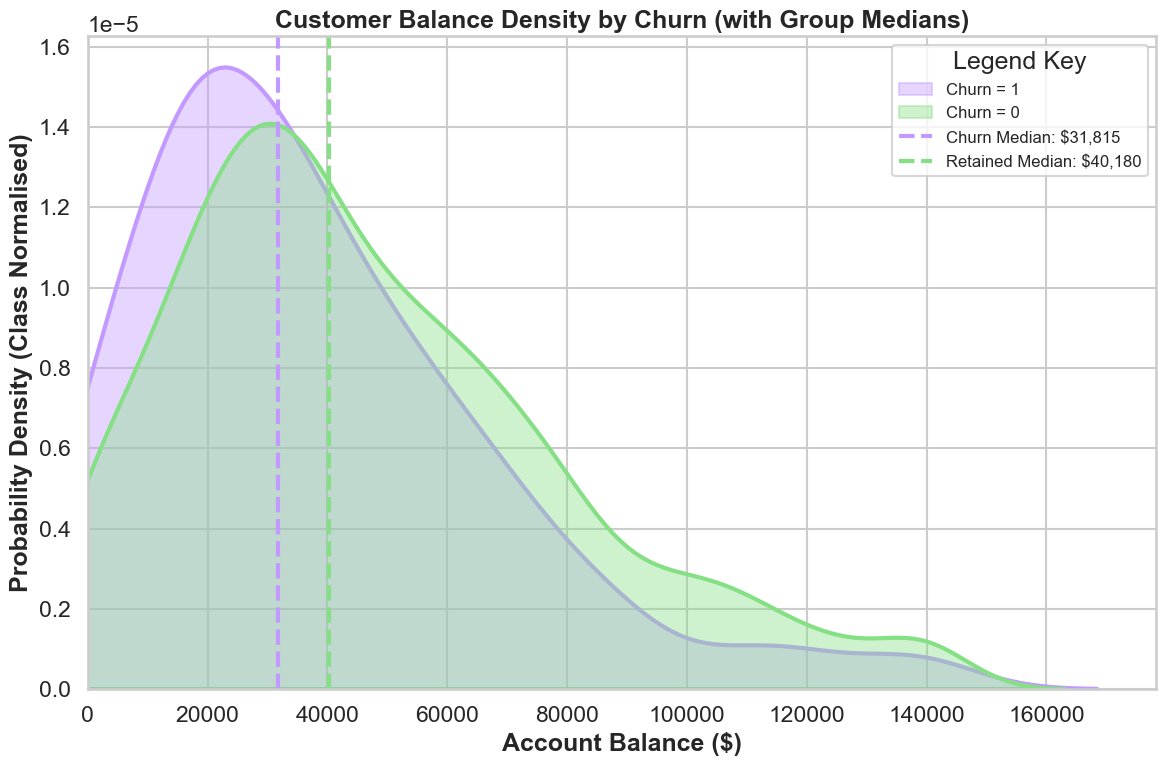

In [21]:
# Plot Balance Density for retained and churn customers to understand distributions
# Read the dataset
df = df_clean.copy()

# Calculate the specific medians for each class
median_churn = df[df['Churn'] == 1]['Balance'].median()
median_no_churn = df[df['Churn'] == 0]['Balance'].median()

# Define the custom light colors
color_safe = '#85e085' # Light Green for Safe (0)
color_churn = '#c299ff' # Light Purple for Churn (1)

# Set up the plot style
sns.set_theme(style="whitegrid", context="talk")
plt.figure(figsize=(12, 8))

# Draw Overlapping KDE Density Plots
ax = sns.kdeplot(
    data=df, 
    x='Balance', 
    hue='Churn', 
    fill=True, 
    common_norm=False, 
    palette=[color_safe, color_churn], 
    alpha=0.4, # Controls the see-through transparency
    linewidth=3
)

# Plot the vertical dashed lines for BOTH means with matching colors
plt.axvline(x=median_churn, color=color_churn, linestyle='--', linewidth=3)
plt.axvline(x=median_no_churn, color=color_safe, linestyle='--', linewidth=3)

# Force the X-axis to start at $0
plt.xlim(left=0)

# Add Titles and Labels
plt.title('Customer Balance Density by Churn (with Group Medians)', fontweight='bold')
plt.xlabel('Account Balance ($)', fontweight='bold')
plt.ylabel('Probability Density (Class Normalised)', fontweight='bold')

# Customise the legend
legend_elements = [
    Patch(facecolor=color_churn, alpha=0.4, edgecolor=color_churn, label='Churn = 1'),
    Patch(facecolor=color_safe, alpha=0.4, edgecolor=color_safe, label='Churn = 0'),
    Line2D([0], [0], color=color_churn, linestyle='--', linewidth=3, label=f'Churn Median: ${median_churn:,.0f}'),
    Line2D([0], [0], color=color_safe, linestyle='--', linewidth=3, label=f'Retained Median: ${median_no_churn:,.0f}')
]
ax.legend(handles=legend_elements, title='Legend Key', fontsize=12)

plt.tight_layout()
# Save the plot as a high-resolution PNG
plt.savefig('Figures\BalanceDensityPlot.png', dpi=300, bbox_inches='tight')
plt.show()

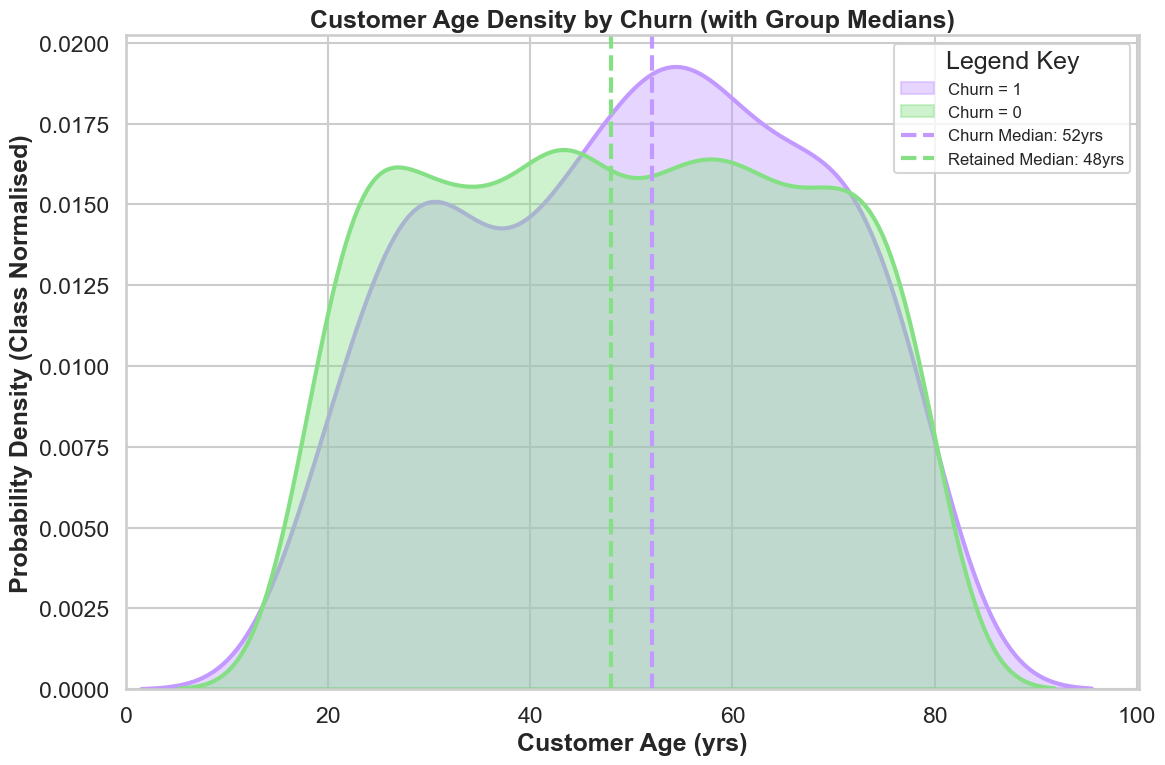

In [22]:
# Plot Balance Age for retained and churn customers to understand distributions
# Read the dataset
df = df_clean.copy()

# Calculate the specific medians for each class
median_churn = df[df['Churn'] == 1]['Age'].median()
median_no_churn = df[df['Churn'] == 0]['Age'].median()

# Define the custom light colors
color_safe = '#85e085' # Light Green for Safe (0)
color_churn = '#c299ff' # Light Purple for Churn (1)

# Set up the plot style
sns.set_theme(style="whitegrid", context="talk")
plt.figure(figsize=(12, 8))

# Draw Overlapping KDE Density Plots
ax = sns.kdeplot(
    data=df, 
    x='Age', 
    hue='Churn', 
    fill=True, 
    common_norm=False, 
    palette=[color_safe, color_churn], 
    alpha=0.4, # Controls the see-through transparency
    linewidth=3
)

# Plot the vertical dashed lines for BOTH means with matching colors
plt.axvline(x=median_churn, color=color_churn, linestyle='--', linewidth=3)
plt.axvline(x=median_no_churn, color=color_safe, linestyle='--', linewidth=3)

# Force the X-axis to start at 0 yrs
plt.xlim(left=0)

# Add Titles and Labels
plt.title('Customer Age Density by Churn (with Group Medians)', fontweight='bold')
plt.xlabel('Customer Age (yrs)', fontweight='bold')
plt.ylabel('Probability Density (Class Normalised)', fontweight='bold')

# Customise the legend
legend_elements = [
    Patch(facecolor=color_churn, alpha=0.4, edgecolor=color_churn, label='Churn = 1'),
    Patch(facecolor=color_safe, alpha=0.4, edgecolor=color_safe, label='Churn = 0'),
    Line2D([0], [0], color=color_churn, linestyle='--', linewidth=3, label=f'Churn Median: {median_churn:,.0f}yrs'),
    Line2D([0], [0], color=color_safe, linestyle='--', linewidth=3, label=f'Retained Median: {median_no_churn:,.0f}yrs')
]
ax.legend(handles=legend_elements, title='Legend Key', fontsize=12)

plt.tight_layout()
# Save the plot as a high-resolution PNG
plt.savefig('Figures\AgeDensityPlot.png', dpi=300, bbox_inches='tight')
plt.show()

In [17]:
# Capture churn risk age bracket

# Load dataset
df = df_clean.copy()
age_churned = df[df['Churn'] == 1]['Age'].dropna()
age_retained = df[df['Churn'] == 0]['Age'].dropna()

# Fit the Kernel Density Estimators (KDE)
kde_churn = gaussian_kde(age_churned)
kde_retain = gaussian_kde(age_retained)

# Create a continuous grid of ages to evaluate
age_grid = np.linspace(df['Age'].min(), df['Age'].max(), 1000)

# Calculate the difference between the two curves
density_diff = kde_churn(age_grid) - kde_retain(age_grid)

# Find the roots (where the curves intersect / difference crosses zero)
zero_crossings = np.where(np.diff(np.sign(density_diff)))[0]
intersection_ages = age_grid[zero_crossings]

print(f"The high-risk age bracket sits precisely between: {intersection_ages[0]:.1f} and {intersection_ages[1]:.1f} years old.")


The high-risk age bracket sits precisely between: 45.1 and 71.6 years old.


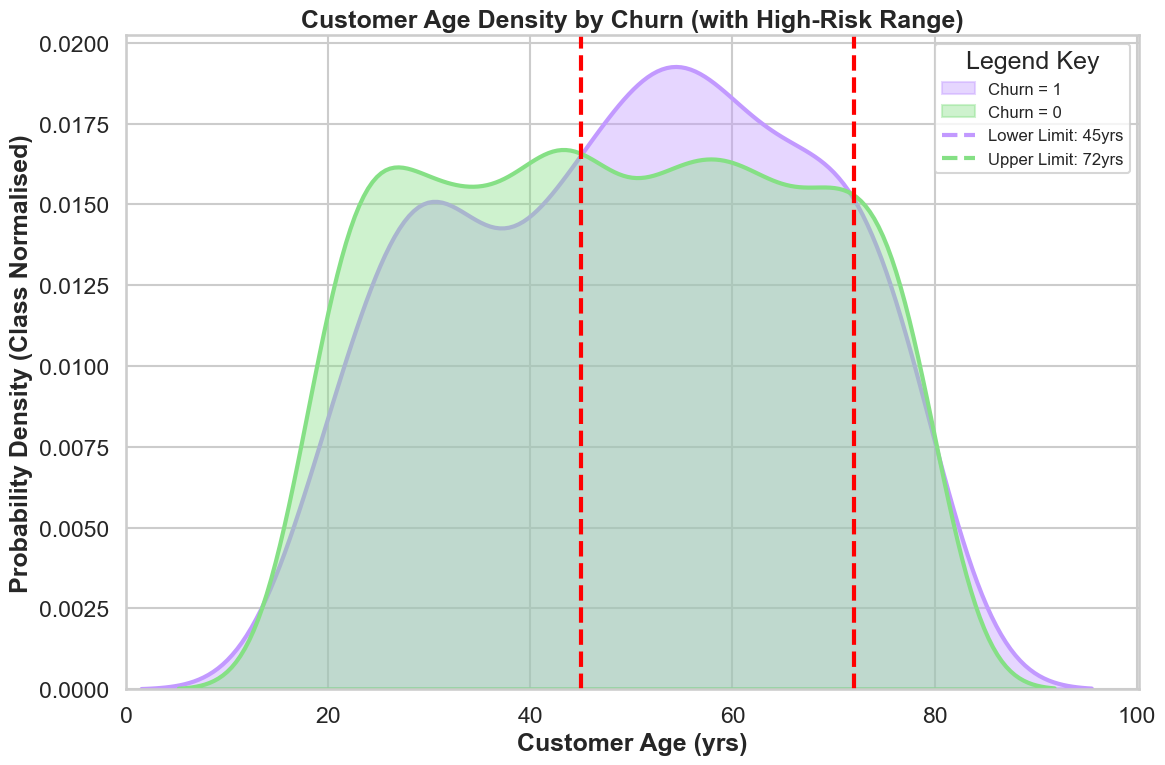

In [23]:
# Plot high risk Age bracket for churn customers 
# Read the dataset
df = df_clean.copy()

# Add high risk age bracket range
lower_age = 45
upper_age = 72

# Define the custom light colors
color_safe = '#85e085' # Light Green for Safe (0)
color_churn = '#c299ff' # Light Purple for Churn (1)

# Set up the plot style
sns.set_theme(style="whitegrid", context="talk")
plt.figure(figsize=(12, 8))

# Draw Overlapping KDE Density Plots
ax = sns.kdeplot(
    data=df, 
    x='Age', 
    hue='Churn', 
    fill=True, 
    common_norm=False, 
    palette=[color_safe, color_churn], 
    alpha=0.4, # Controls the see-through transparency
    linewidth=3
)

# Plot the vertical dashed lines for BOTH means with matching colors
plt.axvline(x=lower_age, color='#FF0000', linestyle='--', linewidth=3)
plt.axvline(x=upper_age, color='#FF0000', linestyle='--', linewidth=3)

# Force the X-axis to start at 0 yrs
plt.xlim(left=0)

# Add Titles and Labels
plt.title('Customer Age Density by Churn (with High-Risk Range)', fontweight='bold')
plt.xlabel('Customer Age (yrs)', fontweight='bold')
plt.ylabel('Probability Density (Class Normalised)', fontweight='bold')

# Customise the legend
legend_elements = [
    Patch(facecolor=color_churn, alpha=0.4, edgecolor=color_churn, label='Churn = 1'),
    Patch(facecolor=color_safe, alpha=0.4, edgecolor=color_safe, label='Churn = 0'),
    Line2D([0], [0], color=color_churn, linestyle='--', linewidth=3, label=f'Lower Limit: {lower_age:,.0f}yrs'),
    Line2D([0], [0], color=color_safe, linestyle='--', linewidth=3, label=f'Upper Limit: {upper_age:,.0f}yrs')
]
ax.legend(handles=legend_elements, title='Legend Key', fontsize=12)

plt.tight_layout()
# Save the plot as a high-resolution PNG
plt.savefig('Figures\HighRiskAgeDensityPlot.png', dpi=300, bbox_inches='tight')
plt.show()

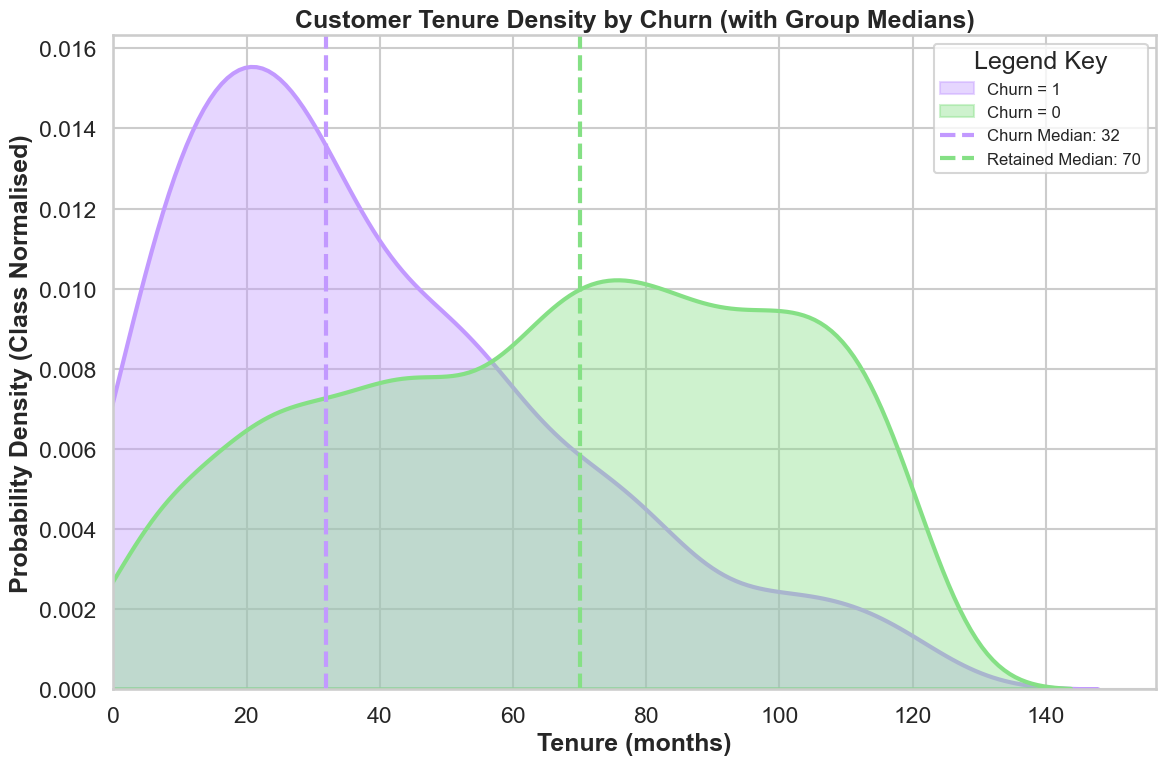

In [20]:
# Read the dataset
df = df_clean.copy()

# Calculate the specific medians for each class
median_churn = df[df['Churn'] == 1]['TenureMonths'].median()
median_no_churn = df[df['Churn'] == 0]['TenureMonths'].median()

# Define the custom light colors
color_safe = '#85e085' # Light Green for Safe (0)
color_churn = '#c299ff' # Light Purple for Churn (1)

# Set up the plot style
sns.set_theme(style="whitegrid", context="talk")
plt.figure(figsize=(12, 8))

# Draw Overlapping KDE Density Plots
ax = sns.kdeplot(
    data=df, 
    x='TenureMonths', 
    hue='Churn', 
    fill=True, 
    common_norm=False, 
    palette=[color_safe, color_churn], 
    alpha=0.4, # Controls the see-through transparency
    linewidth=3
)

# Plot the vertical dashed lines for BOTH means with matching colors
plt.axvline(x=median_churn, color=color_churn, linestyle='--', linewidth=3)
plt.axvline(x=median_no_churn, color=color_safe, linestyle='--', linewidth=3)

# Force the X-axis to start at $0
plt.xlim(left=0)

# Add Titles and Labels
plt.title('Customer Tenure Density by Churn (with Group Medians)', fontweight='bold')
plt.xlabel('Tenure (months)', fontweight='bold')
plt.ylabel('Probability Density (Class Normalised)', fontweight='bold')

# Customise the legend
legend_elements = [
    Patch(facecolor=color_churn, alpha=0.4, edgecolor=color_churn, label='Churn = 1'),
    Patch(facecolor=color_safe, alpha=0.4, edgecolor=color_safe, label='Churn = 0'),
    Line2D([0], [0], color=color_churn, linestyle='--', linewidth=3, label=f'Churn Median: {median_churn:,.0f}'),
    Line2D([0], [0], color=color_safe, linestyle='--', linewidth=3, label=f'Retained Median: {median_no_churn:,.0f}')
]
ax.legend(handles=legend_elements, title='Legend Key', fontsize=12)

plt.tight_layout()
# Save the plot as a high-resolution PNG
plt.savefig('Figures\TenureDensityPlot.png', dpi=300, bbox_inches='tight')
plt.show()

**Churn Cohort Analysis:**

**How This Works**

* **Dynamic Grouping:** Pass a continuous variable like `Balance`, then split the customers into equal-sized buckets (e.g., 5 or 10 cohorts).
* **True Averages:** Instead of placing arbitrary bucket labels on the x-axis, it calculates the *actual mean balance* of that specific cohort.
* **Direct Correlation Visualization:** Creates a standard scatter-and-line plot where you can explicitly track how a numerical increase in the predictor variable maps to a proportional rise or fall in the churn rate.

In [18]:
def plot_cohort_averages(df, predictor, target='Churn', num_bins=10, plotName=''):
    """
    Plots the cohort average of the target (y-axis) versus 
    the cohort average of the predictor (x-axis).
    """
    temp_df = df.copy()
    
    # Assign data points to cohorts
    if pd.api.types.is_numeric_dtype(temp_df[predictor]) and temp_df[predictor].nunique() > num_bins:
        # qcut with rank handles duplicate values (like many $0 balances) cleanly
        temp_df['Cohort'] = pd.qcut(temp_df[predictor].rank(method='first'), q=num_bins, labels=False)
    else:
        # Leave as is if it's categorical or has very few distinct values
        temp_df['Cohort'] = temp_df[predictor]
        
    # Calculate the mean of the predictor and the mean of the target for each cohort
    cohort_data = temp_df.groupby('Cohort')[[predictor, target]].mean().reset_index(drop=True)
    
    # Sort by the predictor to ensure the line plot connects chronologically/numerically
    cohort_data = cohort_data.sort_values(by=predictor)
    
    # Plotting
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(9, 5))
    
    sns.lineplot(
        data=cohort_data, 
        x=predictor, 
        y=target, 
        marker='o', 
        color='teal', 
        linewidth=2, 
        markersize=8
    )
    
    # Formatting
    plt.title(f'Cohort Analysis: Avg {predictor} vs. Avg {target} Rate', fontweight='bold')
    plt.xlabel(f'Average {predictor} (per cohort)')
    plt.ylabel(f'Average {target} Rate')
    plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    
    plt.tight_layout()
    # Save the plot as a high-resolution PNG
    plt.savefig(f"Figures\{plotName}_CohortAnalysis.png", dpi=300, bbox_inches='tight')
    plt.show()

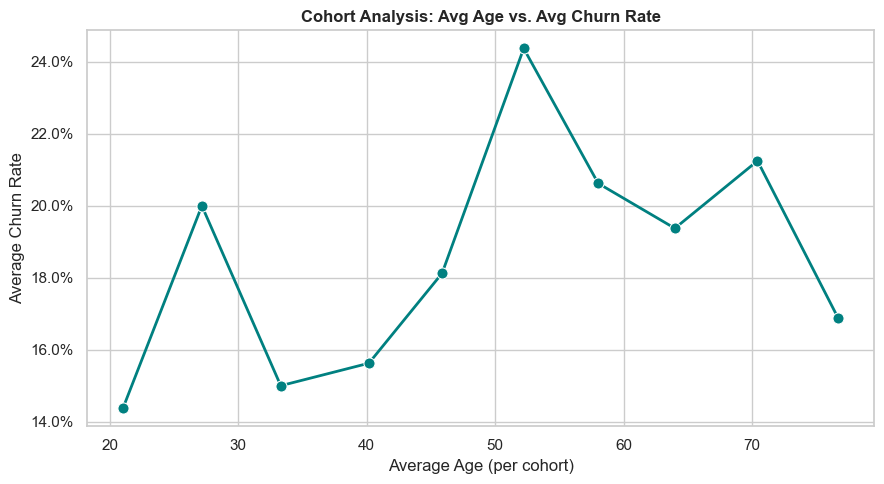

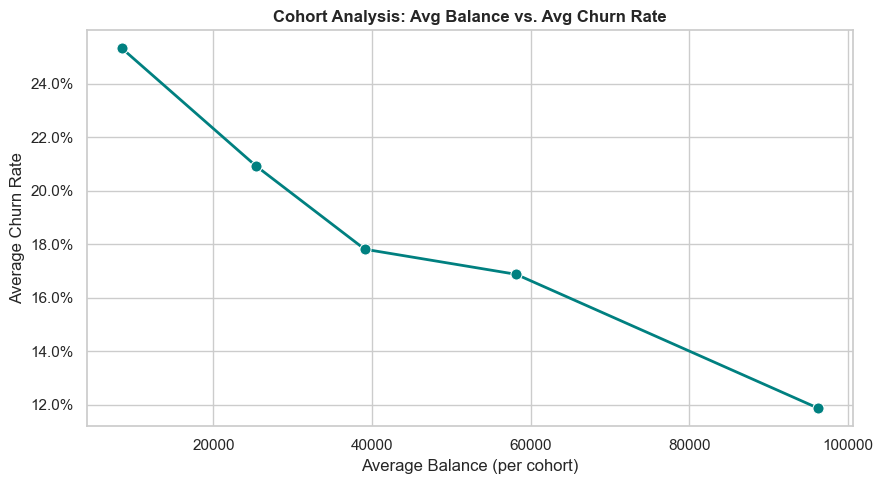

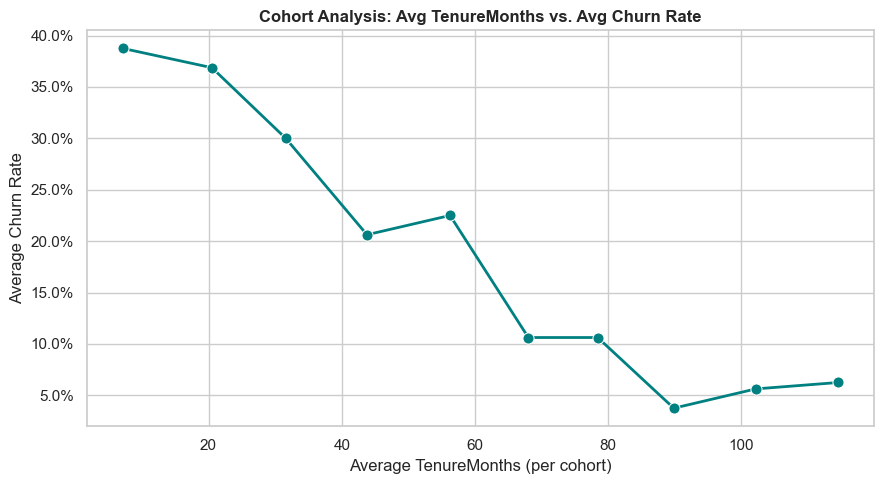

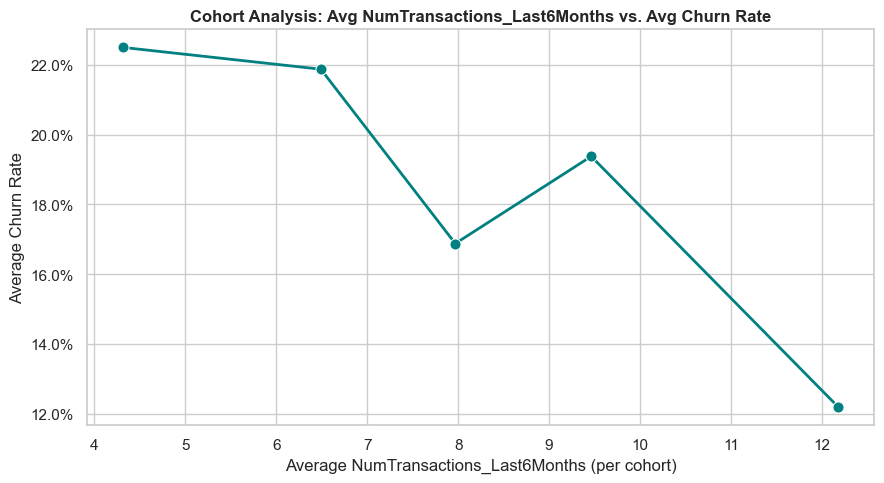

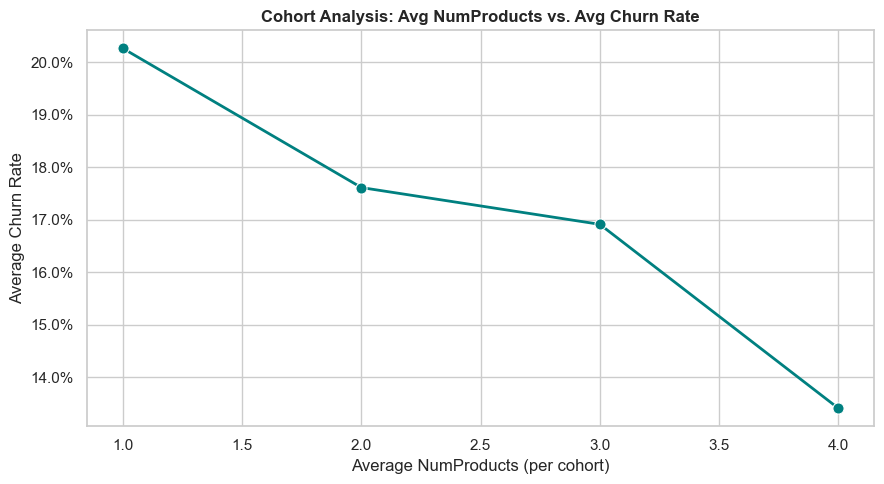

In [19]:
# Plot cohort analysis on statistically significant continuous predictors
plot_cohort_averages(df_clean, predictor='Age', num_bins=10, plotName='Age')
plot_cohort_averages(df_clean, predictor='Balance', num_bins=5, plotName='Balance')
plot_cohort_averages(df_clean, predictor='TenureMonths', num_bins=10, plotName='TenureMonths')
plot_cohort_averages(df_clean, predictor='NumTransactions_Last6Months', num_bins=5, plotName='NumTransactions_Last6Months')
plot_cohort_averages(df_clean, predictor='NumProducts', num_bins=5, plotName='NumProducts')

**Key Insights from the Output:**



## 8. Churned vs retained — categorical variables
Investigate churn across categorical customer characteristics.

Possible variables:
- `Gender`
- `IsActiveMember`

Compare **churn rates** between groups rather than relying only on raw counts.

In [20]:
# Compare categorical variables by churn status

# Check categorical predictor association churn by Chi-Sq test

# Check Gender for association with churn
# Build a contingency table (cross-tabulation)
contingency_table = pd.crosstab(df_clean['Is_Female'], df_clean['Churn'])
print("--- Contingency Table ---")
print(contingency_table, "\n")

# 3Perform the Chi-Square Test
# correction=True applies Yates' correction for 2x2 tables automatically
chi2_stat, p_value, dof, expected_frequencies = chi2_contingency(contingency_table)

# Interpret the statistical results
print("--- Is_Female Test Results ---")
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"P-value:             {p_value:.4e}")
print(f"Degrees of Freedom:   {dof}")


--- Contingency Table ---
Churn        0    1
Is_Female          
0          642  152
1          661  145 

--- Is_Female Test Results ---
Chi-Square Statistic: 0.2799
P-value:             5.9678e-01
Degrees of Freedom:   1


In [21]:
# Check Active Member for association with churn
# Build a contingency table (cross-tabulation)
contingency_table = pd.crosstab(df_clean['IsActiveMember_Flag'], df_clean['Churn'])
print("--- Contingency Table ---")
print(contingency_table, "\n")

# 3Perform the Chi-Square Test
# correction=True applies Yates' correction for 2x2 tables automatically
chi2_stat, p_value, dof, expected_frequencies = chi2_contingency(contingency_table)

# Interpret the statistical results
print("--- IsActiveMenber_Flag Test Results ---")
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"P-value:             {p_value:.4e}")
print(f"Degrees of Freedom:   {dof}")

--- Contingency Table ---
Churn                  0    1
IsActiveMember_Flag          
0                    556  218
1                    747   79 

--- IsActiveMenber_Flag Test Results ---
Chi-Square Statistic: 90.2318
P-value:             2.1183e-21
Degrees of Freedom:   1


In [22]:
# Check and compare strength of relationship of categorical variables with churn by Cramer's V (0-1, perfect=1)

# Function to calculate Cramer's V
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# Apply to your categorical columns
categorical_cols = ['Is_Female', 'IsActiveMember_Flag'] # Add your flag variables here
results = []

for col in categorical_cols:
    cv_score = cramers_v(df_clean[col], df_clean['Churn'])
    mi_score = mutual_info_score(df_clean[col], df_clean['Churn'])
    results.append({'Variable': col, 'Cramers_V': cv_score, 'Mutual_Information': mi_score})

# Rank the results
ranking_df = pd.DataFrame(results).sort_values(by='Cramers_V', ascending=False)
print(ranking_df)

              Variable  Cramers_V  Mutual_Information
1  IsActiveMember_Flag    0.23623            0.029398
0            Is_Female    0.00000            0.000110


In [23]:
# Group by the active member flag and calculate the mean of the Churn column
# Calculate the percentages of  churn between active and nonactive members
churn_rates = df.groupby('IsActiveMember_Flag')['Churn'].mean() * 100

print("Churn Percentage by Active Status:")
print(churn_rates.round(2).astype(str) + '%')

Churn Percentage by Active Status:
IsActiveMember_Flag
0    28.17%
1     9.56%
Name: Churn, dtype: object


**Key Insights from the Output:**

Churn predictor IsActiveMember_Flag (Chi sq test p-value=2.1183e-21) with Cramers_V=0.23623 has moderate (0.2->0.4) relationship. 

Churn predictor Is_Female (Chi sq test p-value=5.9678e-01) with Cramers_V=0 has weak (<0.1) relationship.

Active members churn at 9.56% while nonactive members churn at 28.17%

## 9. Visualise important patterns
Create simple charts for potentially important relationships.

Keep plots:
- easy to interpret
- clearly labelled
- relevant to the business question

Not every exploratory plot needs to appear in the final report.

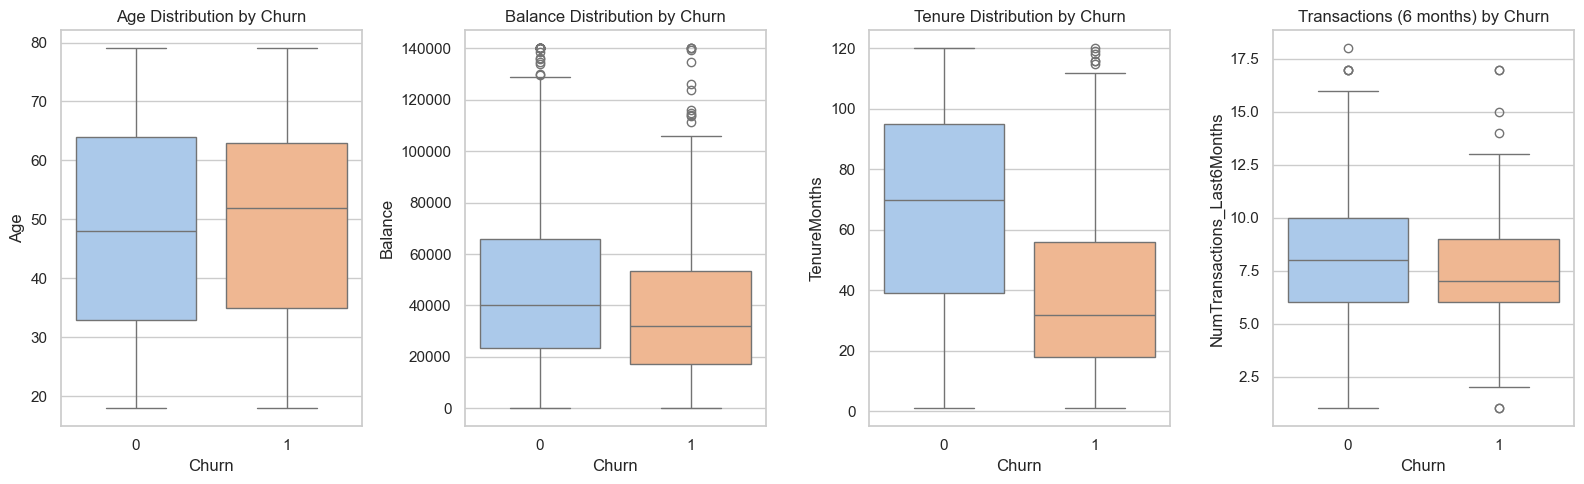

In [24]:
# Set visual style
sns.set_theme(style="whitegrid")

# Boxplots for Continuous Variables
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
sns.boxplot(data=df_clean, x='Churn', y='Age', ax=axes[0], palette='pastel')
axes[0].set_title('Age Distribution by Churn')

sns.boxplot(data=df_clean, x='Churn', y='Balance', ax=axes[1], palette='pastel')
axes[1].set_title('Balance Distribution by Churn')

sns.boxplot(data=df_clean, x='Churn', y='TenureMonths', ax=axes[2], palette='pastel')
axes[2].set_title('Tenure Distribution by Churn')

sns.boxplot(data=df_clean, x='Churn', y='NumTransactions_Last6Months', ax=axes[3], palette='pastel')
axes[3].set_title('Transactions (6 months) by Churn')

plt.tight_layout()
# Save the plot as a high-resolution PNG
plt.savefig('Figures\EDA_BoxPlots.png', dpi=300, bbox_inches='tight')
plt.show()

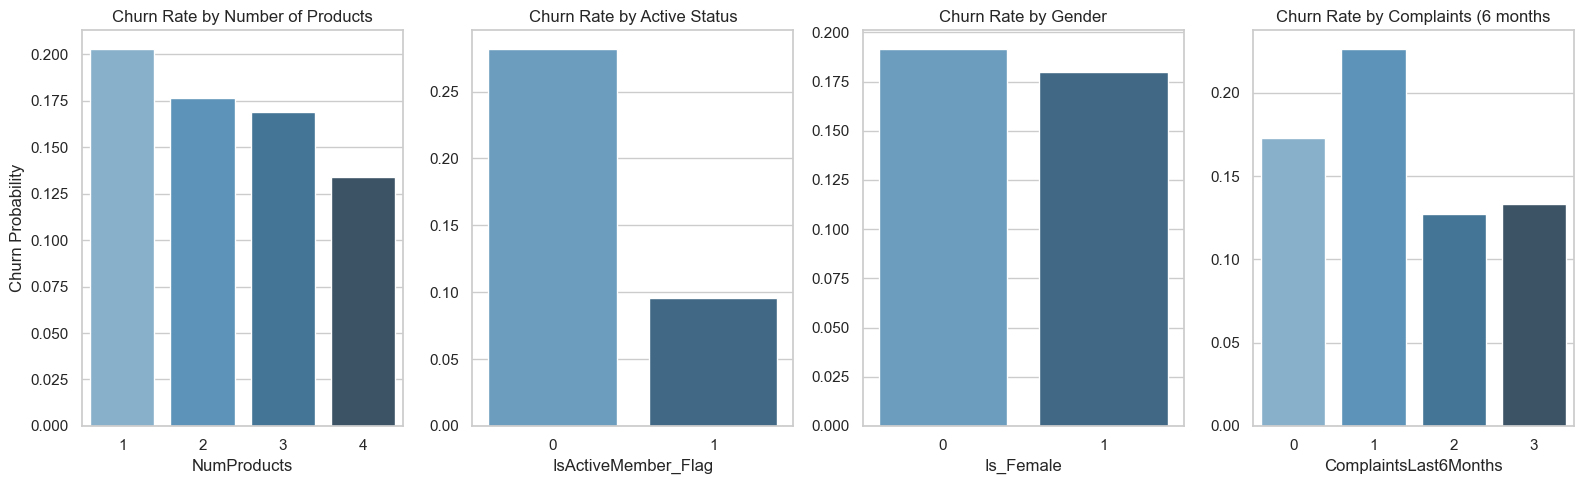

In [25]:
# Bar Plots for Categorical Churn Rates
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
sns.barplot(data=df_clean, x='NumProducts', y='Churn', errorbar=None, ax=axes[0], palette='Blues_d')
axes[0].set_title('Churn Rate by Number of Products')
axes[0].set_ylabel('Churn Probability')

sns.barplot(data=df_clean, x='IsActiveMember_Flag', y='Churn', errorbar=None, ax=axes[1], palette='Blues_d')
axes[1].set_title('Churn Rate by Active Status')
axes[1].set_ylabel('')

sns.barplot(data=df_clean, x='Is_Female', y='Churn', errorbar=None, ax=axes[2], palette='Blues_d')
axes[2].set_title('Churn Rate by Gender')
axes[2].set_ylabel('')

sns.barplot(data=df_clean, x='ComplaintsLast6Months', y='Churn', errorbar=None, ax=axes[3], palette='Blues_d')
axes[3].set_title('Churn Rate by Complaints (6 months')
axes[3].set_ylabel('')

plt.tight_layout()
# Save the plot as a high-resolution PNG
plt.savefig('Figures\EDA_BarPlots.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. Investigate potential churn indicators
Look for specific patterns that could become testable hypotheses.

The final Task 1 outcome requires **at least two hypotheses supported by numbers from the data**.

Suggested structure:

> **Group / condition A:** churn rate = ___  
> **Group / condition B:** churn rate = ___  
> **What this suggests:** ___

In [26]:
# Calculate customer profile evidence for potential churn hypothesis

"""
The "Empty Vault" Trigger (Balance)

Not active with no account balance.
"""

# Define the condition: Inactive member AND Balance of $0 (using <1000 not as good predictor)
condition = (df_clean['IsActiveMember_Flag'] == 0) & (df_clean['Balance'] == 0)

# Filter the data to isolate these specific customers
subset = df_clean[condition]

# Calculate the churn rate and total count
churn_percentage = subset['Churn'].mean() * 100
customer_count = len(subset)

print(f"Number of inactive, low-balance customers: {customer_count}")
print(f"Churn rate for this segment: {churn_percentage:.1f}%")

Number of inactive, low-balance customers: 44
Churn rate for this segment: 31.8%


In [27]:
"""
The Over-Stuffed Newcomer (Tenure -> Products)

The highest-risk profile here is the "new but overloaded" customer—someone with under 24 months of history 
who has been aggressively cross-sold multipleb (3+) products. Because they have not yet built foundational loyalty (Tenure), 
forcing complex product adoption (NumProducts) creates overwhelming friction that leads directly to the exit.
"""

# Define the exact conditions: Tenure less than 24 months AND 3 or more products
condition = (df_clean['TenureMonths'] < 24) & (df_clean['NumProducts'] >= 3)

# Filter the dataframe to isolate this specific segment
subset = df_clean[condition]

# Calculate the churn rate and total count
churn_percentage = subset['Churn'].mean() * 100
customer_count = len(subset)

print(f"Number of new customers with 3+ products: {customer_count}")
print(f"Churn rate for this segment: {churn_percentage:.1f}%")

Number of new customers with 3+ products: 52
Churn rate for this segment: 42.3%


In [28]:
"""
The Disengaged "Silent Churner" (Complaints)

The absence of recent complaints combined with low balances often flags a customer who has already mentally checked out. 
Rather than indicating satisfaction, this zero-friction state frequently represents a deeply disengaged account. 
The customer hasn't complained because they have already moved their primary banking activities to a competitor and 
simply haven't bothered to officially close their Sydney Bank account yet.
"""

# Define the "Silent Churner" (0 complaints AND balance under $1,000)
silent_condition = (df_clean['ComplaintsLast6Months'] == 0) & (df_clean['Balance'] < 1000)
silent_churners = df_clean[silent_condition]

# Define the "Satisfied Customer" (0 complaints AND balance over $1,000)
satisfied_condition = (df_clean['ComplaintsLast6Months'] == 0) & (df['Balance'] >= 1000)
satisfied_customers = df_clean[satisfied_condition]

# Calculate and compare the results
print("--- The 'Silent Churner' Profile (No Complaints, Low/Zero Balance) ---")
print(f"Count: {len(silent_churners)}")
print(f"Churn Rate: {silent_churners['Churn'].mean() * 100:.1f}%\n")

print("--- The 'Satisfied' Profile (No Complaints, High Balance) ---")
print(f"Count: {len(satisfied_customers)}")
print(f"Churn Rate: {satisfied_customers['Churn'].mean() * 100:.1f}%")

--- The 'Silent Churner' Profile (No Complaints, Low/Zero Balance) ---
Count: 60
Churn Rate: 18.3%

--- The 'Satisfied' Profile (No Complaints, High Balance) ---
Count: 941
Churn Rate: 17.2%


In [29]:
"""
The Mid-Life Wealth Shift (Age -> Balance)

While age does not trigger churn directly in the network, it dictates balance size. 
Customers entering their late 40s to early 50s undergo massive financial shifts (mortgages, college funds, retirement planning). 
The network captures this by showing that age influences balance volatility, which then gets passed downstream as an elevated, indirect churn risk.
"""

# Assign clean dataset to another df
df = df_clean.copy()

# Define Age Segments isolating the "Mid-Life" cohort (e.g., 46-55)
bins = [0, 35, 45, 55, 100]
labels = ['Young (<35)', 'Early Mid-Life (36-45)', 'Mid-Life Shift (46-55)', 'Senior (>55)']
df['Wealth_Stage'] = pd.cut(df['Age'], bins=bins, labels=labels)

# 3. Calculate Mean Balance and Balance Volatility (Standard Deviation) by Stage
wealth_metrics = df.groupby('Wealth_Stage', observed=True)['Balance'].agg(['mean', 'std']).round(2)
wealth_metrics.columns = ['Average Balance', 'Balance Volatility (Std Dev)']

print("--- Balance Metrics by Age Stage ---")
print(wealth_metrics)

# 4. Check the direct statistical correlation between Age and Balance
correlation = df['Age'].corr(df['Balance'])
print(f"\nStatistical Correlation between Age and Balance: {correlation:.4f}")

--- Balance Metrics by Age Stage ---
                        Average Balance  Balance Volatility (Std Dev)
Wealth_Stage                                                         
Young (<35)                    43975.39                      32101.68
Early Mid-Life (36-45)         45396.01                      32189.92
Mid-Life Shift (46-55)         45313.76                      31693.47
Senior (>55)                   46573.60                      32083.27

Statistical Correlation between Age and Balance: 0.0229


In [30]:
"""
The Rate Shopper

The Logic: Customers parking large sums in a single account without transacting frequently are often just chasing introductory interest rates. 
They have no sticky ties to the bank and are highly flight-prone.

The Variables: High Balance + 1 Product + Low Transaction Frequency.
"""

# Assign clean dataset to another df
df = df_clean.copy()

# Define the Rate Shopper condition
is_rate_shopper = (df['Balance'] > 75000) & (df['NumProducts'] == 1) & (df['NumTransactions_Last6Months'] <= 2)

# Segment the data into the target group and everyone else
rate_shoppers = df[is_rate_shopper]
other_customers = df[~is_rate_shopper]

# Calculate and compare the churn metrics
print("--- 'Rate Shopper' Profile ---")
print(f"Count: {len(rate_shoppers)}")
# Using an if-statement prevents a division-by-zero error if the segment is empty
if len(rate_shoppers) > 0:
    print(f"Churn Rate: {rate_shoppers['Churn'].mean() * 100:.1f}%\n")
else:
    print("Churn Rate: N/A (0 customers match this profile)\n")

print("--- All Other Customers ---")
print(f"Count: {len(other_customers)}")
print(f"Churn Rate: {other_customers['Churn'].mean() * 100:.1f}%")

--- 'Rate Shopper' Profile ---
Count: 2
Churn Rate: 50.0%

--- All Other Customers ---
Count: 1598
Churn Rate: 18.5%


In [31]:
"""
The Frustrated Power User

The Logic: These are highly engaged customers deeply embedded in the bank's ecosystem. 
If they are actively transacting across multiple products but register a complaint, they are experiencing acute friction. 
Losing them damages the bank's bottom line significantly.

The Variables: High Transaction Frequency + Multiple Products + Complaint Flag.
"""

# Assign clean dataset to another df
df = df_clean.copy()

# 2. Recreate the Complaint Flag (if not already saved in your CSV)
df['Complaints_Flag'] = (df['ComplaintsLast6Months'] > 0).astype(int)

# 3. Define the Frustrated Power User condition
is_frustrated_power = (df['NumTransactions_Last6Months'] >= 10) & (df['NumProducts'] >= 2) & (df['Complaints_Flag'] == 1)

# 4. Segment the data
power_users_at_risk = df[is_frustrated_power]
other_customers = df[~is_frustrated_power]

# 5. Calculate and compare the churn metrics
print("--- 'Frustrated Power User' Profile ---")
print(f"Count: {len(power_users_at_risk)}")
if len(power_users_at_risk) > 0:
    print(f"Churn Rate: {power_users_at_risk['Churn'].mean() * 100:.1f}%\n")
else:
    print("Churn Rate: N/A (0 customers match this profile)\n")

print("--- All Other Customers ---")
print(f"Count: {len(other_customers)}")
print(f"Churn Rate: {other_customers['Churn'].mean() * 100:.1f}%")

--- 'Frustrated Power User' Profile ---
Count: 87
Churn Rate: 16.1%

--- All Other Customers ---
Count: 1513
Churn Rate: 18.7%


In [32]:
"""
The Stagnant Veteran

The Logic: Customers who survived the high-risk "New" phase but never deepened their banking relationship. 
Because they only hold one product and have drifted into inactivity, they are prime targets for competitor 
acquisition campaigns.

The Variables: Established Tenure (25–60 months) + 1 Product + Inactive.

"""
# Assign clean dataset to another df
df = df_clean.copy()

# 2. Define the Stagnant Veteran condition
is_stagnant_veteran = (df['TenureMonths'].between(25, 60)) & (df['NumProducts'] == 1) & (df['IsActiveMember_Flag'] == 0)

# 3. Segment the data into the target group and everyone else
stagnant_veterans = df[is_stagnant_veteran]
other_customers = df[~is_stagnant_veteran]

# 4. Calculate and compare the churn metrics
print("--- 'Stagnant Veteran' Profile ---")
print(f"Count: {len(stagnant_veterans)}")
if len(stagnant_veterans) > 0:
    print(f"Churn Rate: {stagnant_veterans['Churn'].mean() * 100:.1f}%\n")
else:
    print("Churn Rate: N/A (0 customers match this profile)\n")

print("--- All Other Customers ---")
print(f"Count: {len(other_customers)}")
print(f"Churn Rate: {other_customers['Churn'].mean() * 100:.1f}%")

--- 'Stagnant Veteran' Profile ---
Count: 114
Churn Rate: 42.1%

--- All Other Customers ---
Count: 1486
Churn Rate: 16.8%


## 11. Feature Engineering

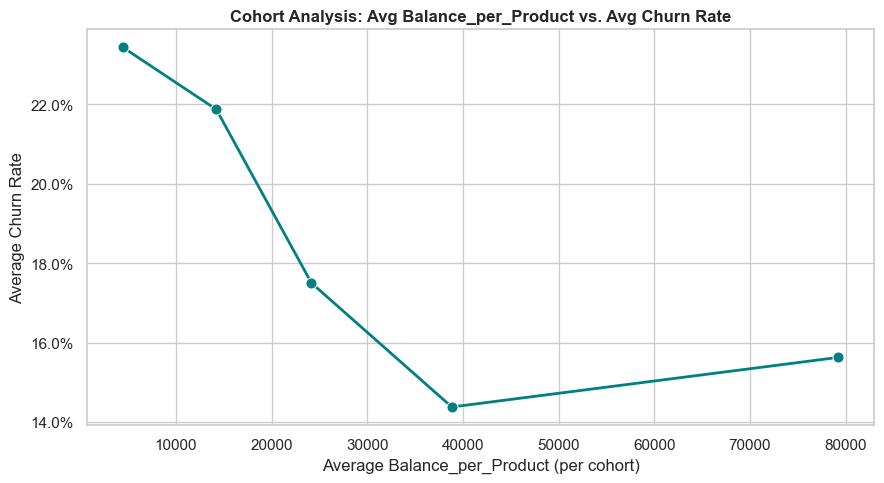

--- Average Balance per Product ---
Retained (0): $33049.09
Churned (1):  $28346.13

--- Statistical Correlation ---
Correlation with Churn: -0.0637

--- Churn Risk by Wealth Brackets ---
Bal_per_Prod_Quartile
(-0.001, 12120.037]      22.2
(12120.037, 24030.85]    21.0
(24030.85, 43549.55]     15.8
(43549.55, 140000.0]     15.2
Name: Churn, dtype: float64


In [33]:
"""
Balance per product

Measure of how concentrated a customer's wealth is across their accounts.
A low balance across multiple products might indicate a customer is testing
the waters before committing
"""

df = df_clean.copy()

# Create the Balance per Product feature
df['Balance_per_Product'] = df['Balance'] / df['NumProducts']

# Cohort Analysis
plot_cohort_averages(df, predictor='Balance_per_Product', num_bins=5)

#  Compare the average Balance per Product for Churned vs. Retained
print("--- Average Balance per Product ---")
avg_balance = df.groupby('Churn')['Balance_per_Product'].mean().round(2)
print(f"Retained (0): ${avg_balance[0]}")
print(f"Churned (1):  ${avg_balance[1]}\n")

# Calculate direct correlation
print("--- Statistical Correlation ---")
correlation = df['Balance_per_Product'].corr(df['Churn'])
print(f"Correlation with Churn: {correlation:.4f}\n")

# Calculate Churn Rate by Quartiles (lowest 25% to highest 25%)
print("--- Churn Risk by Wealth Brackets ---")
# qcut divides the data into 4 equal-sized buckets based on percentiles
df['Bal_per_Prod_Quartile'] = pd.qcut(df['Balance_per_Product'], q=4, duplicates='drop')

# Calculate the churn percentage for each bracket
quartile_churn = df.groupby('Bal_per_Prod_Quartile', observed=True)['Churn'].mean() * 100
print(quartile_churn.round(1))

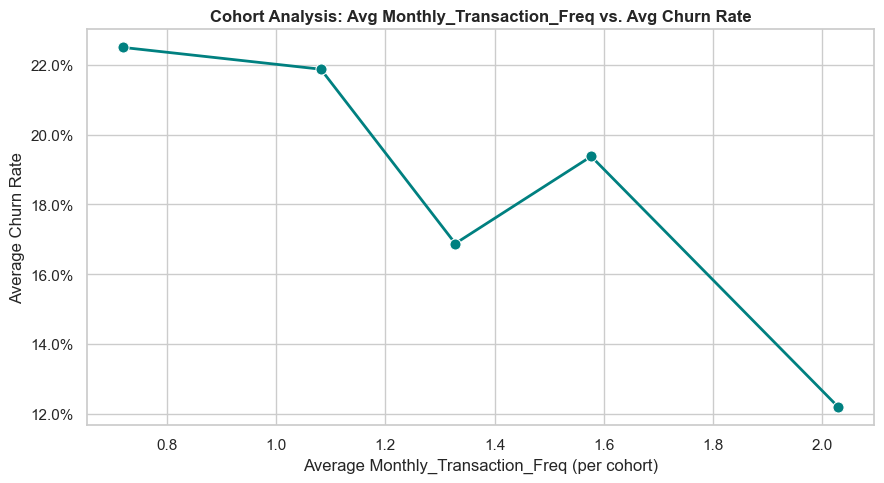

--- Monthly Transaction Rate ---
Retained (0): 1.37
Churned (1):  1.27

--- Statistical Correlation ---
Correlation with Churn: -0.0826

--- Churn Risk by Transaction Rate Brackets ---
Monthly_Transaction_Freq_Quartile
(0.166, 1.0]      21.9
(1.0, 1.333]      18.7
(1.333, 1.667]    19.0
(1.667, 3.0]      12.4
Name: Churn, dtype: float64


In [27]:
"""
Transaction frequency 

Monthly average transaction rate
"""

# Create the monthly transaction frequency feature
df['Monthly_Transaction_Freq'] = df['NumTransactions_Last6Months'] / 6

# Cohort Analysis
plot_cohort_averages(df, predictor='Monthly_Transaction_Freq', num_bins=5)

#  Compare the average Balance per Product for Churned vs. Retained
print("--- Monthly Transaction Rate ---")
avg_balance = df.groupby('Churn')['Monthly_Transaction_Freq'].mean().round(2)
print(f"Retained (0): {avg_balance[0]}")
print(f"Churned (1):  {avg_balance[1]}\n")

# Calculate direct correlation
print("--- Statistical Correlation ---")
correlation = df['Monthly_Transaction_Freq'].corr(df['Churn'])
print(f"Correlation with Churn: {correlation:.4f}\n")

# Calculate Churn Rate by Quartiles (lowest 25% to highest 25%)
print("--- Churn Risk by Transaction Rate Brackets ---")
# qcut divides the data into 4 equal-sized buckets based on percentiles
df['Monthly_Transaction_Freq_Quartile'] = pd.qcut(df['Monthly_Transaction_Freq'], q=4, duplicates='drop')

# Calculate the churn percentage for each bracket
quartile_churn = df.groupby('Monthly_Transaction_Freq_Quartile', observed=True)['Churn'].mean() * 100
print(quartile_churn.round(1))

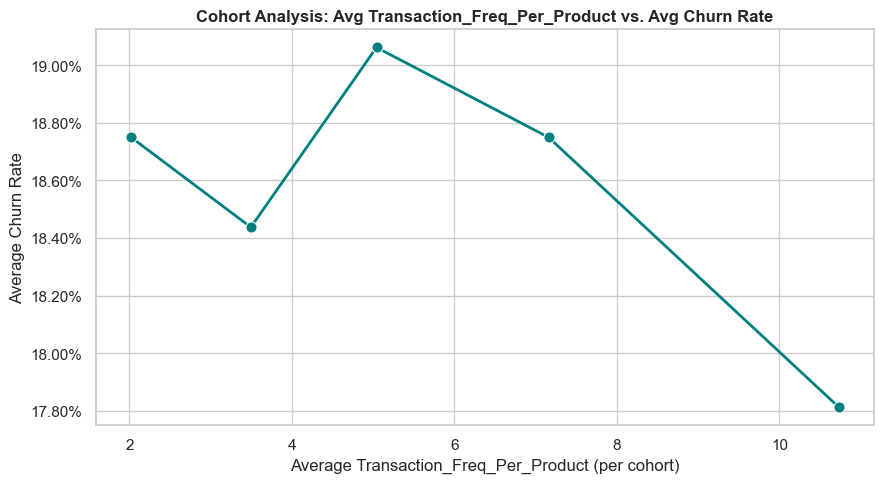

--- Transaction Rate Per Product---
Retained (0): 5.71
Churned (1):  5.58

--- Statistical Correlation ---
Correlation with Churn: -0.0168

--- Churn Risk by Transaction Rate Per Product Brackets ---
Transaction_Freq_Per_Product_Quartile
(0.499, 3.0]    18.8
(3.0, 5.0]      18.7
(5.0, 8.0]      19.0
(8.0, 17.0]     17.5
Name: Churn, dtype: float64


In [33]:
"""
Six Monthly average transaction rate per product
"""

# Create the monthly transaction frequency feature
df['Transaction_Freq_Per_Product'] = df['NumTransactions_Last6Months'] / df['NumProducts']

# Cohort Analysis
plot_cohort_averages(df, predictor='Transaction_Freq_Per_Product', num_bins=5)

#  Compare the average Balance per Product for Churned vs. Retained
print("--- Transaction Rate Per Product---")
avg_balance = df.groupby('Churn')['Transaction_Freq_Per_Product'].mean().round(2)
print(f"Retained (0): {avg_balance[0]}")
print(f"Churned (1):  {avg_balance[1]}\n")

# Calculate direct correlation
print("--- Statistical Correlation ---")
correlation = df['Transaction_Freq_Per_Product'].corr(df['Churn'])
print(f"Correlation with Churn: {correlation:.4f}\n")

# Calculate Churn Rate by Quartiles (lowest 25% to highest 25%)
print("--- Churn Risk by Transaction Rate Per Product Brackets ---")
# qcut divides the data into 4 equal-sized buckets 
df['Transaction_Freq_Per_Product_Quartile'] = pd.qcut(df['Transaction_Freq_Per_Product'], q=4, duplicates='drop')

# Calculate the churn percentage for each bracket
quartile_churn = df.groupby('Transaction_Freq_Per_Product_Quartile', observed=True)['Churn'].mean() * 100
print(quartile_churn.round(1))

In [29]:
"""
Zero Balance Flag

"""
# Create the Zero Balance Flag (1 if Balance is exactly 0, else 0)
df['Is_ZeroBalance'] = (df['Balance'] == 0).astype(int)

# Check categorical predictor association churn by Chi-Sq test

# Check zero contingency table (cross-tabulation)
contingency_table = pd.crosstab(df['Is_ZeroBalance'], df['Churn'])
print("--- Contingency Table ---")
print(contingency_table, "\n")

# 3Perform the Chi-Square Test
# correction=True applies Yates' correction for 2x2 tables automatically
chi2_stat, p_value, dof, expected_frequencies = chi2_contingency(contingency_table)

# Interpret the statistical results
print("--- Is_ZeroBalance' Test Results ---")
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"P-value:             {p_value:.4e}")
print(f"Degrees of Freedom:   {dof}")

--- Contingency Table ---
Churn              0    1
Is_ZeroBalance           
0               1232  273
1                 71   24 

--- Is_ZeroBalance' Test Results ---
Chi-Square Statistic: 2.5470
P-value:             1.1050e-01
Degrees of Freedom:   1


In [30]:
"""
Complaint Flag

"""
# Create the Complaint Flag (1 if any complaints exist, else 0)
df['Complaints_Flag'] = (df['ComplaintsLast6Months'] > 0).astype(int)

# Check categorical predictor association churn by Chi-Sq test

# Check complaint flag for association with churn
# Build a contingency table (cross-tabulation)
contingency_table = pd.crosstab(df['Complaints_Flag'], df['Churn'])
print("--- Contingency Table ---")
print(contingency_table, "\n")

# 3Perform the Chi-Square Test
# correction=True applies Yates' correction for 2x2 tables automatically
chi2_stat, p_value, dof, expected_frequencies = chi2_contingency(contingency_table)

# Interpret the statistical results
print("--- Complaints_Flag' Test Results ---")
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"P-value:             {p_value:.4e}")
print(f"Degrees of Freedom:   {dof}")

--- Contingency Table ---
Churn              0    1
Complaints_Flag          
0                828  173
1                475  124 

--- Complaints_Flag' Test Results ---
Chi-Square Statistic: 2.6752
P-value:             1.0192e-01
Degrees of Freedom:   1


In [31]:
"""
Tenure Product risk

Predictor flag for those customers with a tenure <24 months and having >=3 products
"""

# Create the Tenure-Product Risk Flag 
# (1 if tenure is under 24 months AND products >= 3, else 0)
df['TenureProduct_Risk'] = ((df['TenureMonths'] < 24) & (df['NumProducts'] >= 3)).astype(int)

# Check categorical predictor association churn by Chi-Sq test

# Check complaint flag for association with churn
# Build a contingency table (cross-tabulation)
contingency_table = pd.crosstab(df['TenureProduct_Risk'], df['Churn'])
print("--- Contingency Table ---")
print(contingency_table, "\n")

# Perform the Chi-Square Test
# correction=True applies Yates' correction for 2x2 tables automatically
chi2_stat, p_value, dof, expected_frequencies = chi2_contingency(contingency_table)

# Interpret the statistical results
print("--- TenureProduct_Risk' Test Results ---")
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"P-value:             {p_value:.4e}")
print(f"Degrees of Freedom:   {dof}")

# Check strength of relationship of tenure product risk with churn by Cramer's V (0-1, perfect=1)
# Calculate Cramér's V 
# (Using correction=True accounts for small data samples/Yates' correction)
cramers_v = association(contingency_table, method='cramer', correction=True)

print("\n--- Association Strength ---")
print(f"Cramér's V: {cramers_v:.4f}")

--- Contingency Table ---
Churn                  0    1
TenureProduct_Risk           
0                   1273  275
1                     30   22 

--- TenureProduct_Risk' Test Results ---
Chi-Square Statistic: 18.4560
P-value:             1.7387e-05
Degrees of Freedom:   1

--- Association Strength ---
Cramér's V: 0.1074


In [32]:
"""
Tenure Segments

"""

# Define the exact cut-off points and their corresponding labels
# -1 to 24 (New), 24 to 60 (Established), 60 to infinity (Loyal)
bins = [-1, 24, 60, np.inf]
labels = ['New', 'Established', 'Loyal']

# Create the new categorical feature
df['TenureSegment'] = pd.cut(df['TenureMonths'], bins=bins, labels=labels)

# Look for Tenure segments association with risk of churn
#  Churn Rate by Segment
print("--- Churn Risk by Tenure Segment ---")
# Group by the segment, count total customers, and calculate the churn mean
segment_stats = df.groupby('TenureSegment', observed=True)['Churn'].agg(
    Customer_Count='count', 
    Churn_Rate_Pct='mean'
)
# Convert the mean to a clean percentage
segment_stats['Churn_Rate_Pct'] = (segment_stats['Churn_Rate_Pct'] * 100).round(1)
print(segment_stats)

# The Statistical Proof: Chi-Square Test
print("\n--- Statistical Association (Chi-Square) ---")
# Create a contingency table (cross-tabulation) of the two columns
contingency_table = pd.crosstab(df['TenureSegment'], df['Churn'])

# Run the test
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"P-Value: {p_value:.6f}")

--- Churn Risk by Tenure Segment ---
               Customer_Count  Churn_Rate_Pct
TenureSegment                                
New                       302            37.7
Established               466            25.3
Loyal                     832             7.8

--- Statistical Association (Chi-Square) ---
P-Value: 0.000000


In [33]:
"""
Age Brackets

"""
# Define the exact cut-off points and labels
bins = [0, 30, 45, 60, np.inf]
labels = ['18-30', '31-45', '46-60', '61+']

# Create the Age Bracket categorical feature
df['Age_Bracket'] = pd.cut(df['Age'], bins=bins, labels=labels)

# # Look for Age Bracket association with risk of churn
print("--- Churn Risk by Age Bracket ---")
# Group by the bracket, count total customers, and calculate the churn mean
age_stats = df.groupby('Age_Bracket', observed=True)['Churn'].agg(
    Customer_Count='count', 
    Churn_Rate_Pct='mean'
)
# Convert the mean to a clean percentage for easy reading
age_stats['Churn_Rate_Pct'] = (age_stats['Churn_Rate_Pct'] * 100).round(1)
print(age_stats)

# The Statistical Proof: Chi-Square Test
print("\n--- Statistical Association (Chi-Square) ---")
# Create a contingency table (cross-tabulation) of the two columns
contingency_table = pd.crosstab(df['Age_Bracket'], df['Churn'])

# Run the test
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"P-Value: {p_value:.6f}")

--- Churn Risk by Age Bracket ---
             Customer_Count  Churn_Rate_Pct
Age_Bracket                                
18-30                   333            17.1
31-45                   375            16.3
46-60                   402            20.9
61+                     490            19.4

--- Statistical Association (Chi-Square) ---
P-Value: 0.329167


In [37]:
"""
Empty Volt flag

None active customers with $0 balance
"""
#Create the Empty Vault Flag (1 if inactive AND zero balance, else 0)
df['Empty_Vault_Flag'] = ((df['IsActiveMember_Flag'] == 0) & (df['Balance'] == 0)).astype(int)

# Check complaint flag for association with churn
# Build a contingency table (cross-tabulation)
contingency_table = pd.crosstab(df['Empty_Vault_Flag'], df['Churn'])
print("--- Contingency Table ---")
print(contingency_table, "\n")

# Perform the Chi-Square Test
# correction=True applies Yates' correction for 2x2 tables automatically
chi2_stat, p_value, dof, expected_frequencies = chi2_contingency(contingency_table)

# Interpret the statistical results
print("--- Empty_Vault_Flag' Test Results ---")
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"P-value:             {p_value:.4e}")
print(f"Degrees of Freedom:   {dof}")

# Check strength of relationship of Empty_Vault_Flag with churn by Cramer's V (0-1, perfect=1)
# Calculate Cramér's V 
# (Using correction=True accounts for small data samples/Yates' correction)
cramers_v = association(contingency_table, method='cramer', correction=True)

print("\n--- Association Strength ---")
print(f"Cramér's V: {cramers_v:.4f}")

--- Contingency Table ---
Churn                0    1
Empty_Vault_Flag           
0                 1273  283
1                   30   14 

--- Empty_Vault_Flag' Test Results ---
Chi-Square Statistic: 4.3960
P-value:             3.6023e-02
Degrees of Freedom:   1

--- Association Strength ---
Cramér's V: 0.0524


In [40]:
"""
Stagnant Veteran

Customer with 25-26 months tenur, 1 product and not active
"""

# Create the Stagnant Veteran Flag (1 if all conditions are met, else 0)
df['Stagnant_Veteran_Flag'] = (
    (df['TenureMonths'].between(25, 60)) & 
    (df['NumProducts'] == 1) & 
    (df['IsActiveMember_Flag'] == 0)
).astype(int)

# Check Stagnant_Veteran_Flag flag for association with churn
# Build a contingency table (cross-tabulation)
contingency_table = pd.crosstab(df['Stagnant_Veteran_Flag'], df['Churn'])
print("--- Contingency Table ---")
print(contingency_table, "\n")

# Perform the Chi-Square Test
# correction=True applies Yates' correction for 2x2 tables automatically
chi2_stat, p_value, dof, expected_frequencies = chi2_contingency(contingency_table)

# Interpret the statistical results
print("--- Stagnant_Veteran_Flag' Test Results ---")
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"P-value:             {p_value:.4e}")
print(f"Degrees of Freedom:   {dof}")

# Check strength of relationship of Stagnant_Veteran_Flag with churn by Cramer's V (0-1, perfect=1)
# Calculate Cramér's V 
# (Using correction=True accounts for small data samples/Yates' correction)
cramers_v = association(contingency_table, method='cramer', correction=True)

print("\n--- Association Strength ---")
print(f"Cramér's V: {cramers_v:.4f}")

--- Contingency Table ---
Churn                     0    1
Stagnant_Veteran_Flag           
0                      1237  249
1                        66   48 

--- Stagnant_Veteran_Flag' Test Results ---
Chi-Square Statistic: 43.3437
P-value:             4.5922e-11
Degrees of Freedom:   1

--- Association Strength ---
Cramér's V: 0.1646


A p-value of <0.05 combined with a Cramer's V of 0.1 means your feature is mathematically real, but its individual impact is relatively weak. This is a classic hallmark of working with large datasets and is exactly what you should expect to see in banking analytics.

**The P-Value (The Lie Detector)**
The p-value only answers one question: *Is this relationship just random luck?* Because your dataset likely has thousands of rows, it is very easy for a statistical test to detect tiny differences. If a segment's churn rate is 21% while the baseline is 20%, a large sample size will flag that as highly significant (p < 0.05), even though the absolute difference is only 1%.

**Cramer's V (The Muscle)**
Cramer's V answers a different question: *How strong is this relationship?* It ranges from 0 to 1. A score of 0.1 confirms what the percentages probably show: this specific flag (like the Empty Vault) slightly elevates churn risk, but it is not a silver bullet that predicts churn all by itself.

**Should you add them to your training data?**
Yes, absolutely. You should feed these engineered flags into your model for two major reasons:

* **Machine Learning Thrives on Weak Signals:** Models like Random Forests are specifically designed to combine multiple weak predictors (like your 0.1 Cramer's V flags) into a single, highly accurate prediction. While an "Empty Vault" alone might not predict churn perfectly, an "Empty Vault" combined with a "Stagnant Veteran" and a "Mid-Life Age Bracket" creates a highly toxic churn profile that the algorithm will easily catch.
* **Let the Model Do the Sorting:** Your job in feature engineering is to provide logical, business-driven signals. It is the algorithm's job to weigh them. If a feature truly adds no value, the Lasso (L1) penalty in your Logistic Regression will shrink its coefficient to zero, and your Random Forest will simply drop it to the bottom of the Feature Importance chart.


In [41]:
df.head(5)

,Age,TenureMonths,NumProducts,Balance,NumTransactions_Last6Months,ComplaintsLast6Months,Churn,Is_Female,IsActiveMember_Flag,Balance_per_Product,Bal_per_Prod_Quartile,Monthly_Transaction_Freq,Monthly_Transaction_Freq_Quartile,Is_ZeroBalance,Complaints_Flag,TenureProduct_Risk,TenureSegment,Age_Bracket,Empty_Vault_Flag,Stagnant_Veteran_Flag
0,74,105,1,26860.99,7,1,0,1,1,26860.990,"(24030.85, 43549.55]",1.166667,"(1.0, 1.333]",0,1,0,Loyal,61+,0,0
1,26,46,1,28801.87,5,2,0,1,1,28801.870,"(24030.85, 43549.55]",0.833333,"(0.166, 1.0]",0,1,0,Established,18-30,0,0
2,36,81,2,15813.65,15,0,0,1,0,7906.825,"(-0.001, 12120.037]",2.500000,"(1.667, 3.0]",0,0,0,Loyal,31-45,0,0
3,53,86,1,91533.81,10,0,0,0,1,91533.810,"(43549.55, 140000.0]",1.666667,"(1.333, 1.667]",0,0,0,Loyal,46-60,0,0
4,69,117,2,72984.53,11,2,0,0,0,36492.265,"(24030.85, 43549.55]",1.833333,"(1.667, 3.0]",0,1,0,Loyal,61+,0,0


In [42]:
# Add selected engineered features to clean model data set and save

# Define the specific columns you want to bring over from your source dataframe
new_features = df[['TenureProduct_Risk', 'Empty_Vault_Flag', 'Stagnant_Veteran_Flag', 'Age_Bracket', 'TenureSegment']]

# Concatenate them side-by-side with your training dataframe
df_clean_eng = pd.concat([df_clean, new_features], axis=1)

# Save to CSV
df_clean_eng.to_csv('sydney_bank_customer_churn_cleaned_eng.csv', index=False)

In [43]:
df_clean_eng.head(5)

,Age,TenureMonths,NumProducts,Balance,NumTransactions_Last6Months,ComplaintsLast6Months,Churn,Is_Female,IsActiveMember_Flag,TenureProduct_Risk,Empty_Vault_Flag,Stagnant_Veteran_Flag,Age_Bracket,TenureSegment
0,74,105,1,26860.99,7,1,0,1,1,0,0,0,61+,Loyal
1,26,46,1,28801.87,5,2,0,1,1,0,0,0,18-30,Established
2,36,81,2,15813.65,15,0,0,1,0,0,0,0,31-45,Loyal
3,53,86,1,91533.81,10,0,0,0,1,0,0,0,46-60,Loyal
4,69,117,2,72984.53,11,2,0,0,0,0,0,0,61+,Loyal


Logistic Regression and Random Forest models, you should convert the `Age_Bracket` feature into dummy variables.

**Why it matters for your pipeline:**

* **Algorithm Requirements:** Logistic Regression mathematically cannot process text strings like "18-30". It will throw an error unless every column is strictly numeric.
* **Avoiding the Dummy Variable Trap:** When converting categories for linear models, you must drop one category to serve as the baseline (e.g., dropping "18-30" so the model measures how the older brackets perform *compared* to the youngest group). If you don't drop one, the variables become perfectly collinear, which distorts the logistic regression's coefficients.
* **The Two-File Strategy:** Best practice in data science is to save two versions of your data. Save a `churn_master_features.csv` that keeps the readable text labels for presentations or visualization tools, and a `churn_model_ready.csv` where everything is dummy-encoded as 1s and 0s specifically for model training.

By using `drop_first=True`, pandas will automatically create columns like `Age_Bracket_31-45`, `Age_Bracket_46-60`, and `Age_Bracket_61+`, populated entirely with 1s and 0s, leaving the 18-30 group hidden as the mathematical baseline.

## 12. Select key Task 1 patterns
From the exploratory analysis, select at least **three specific variables** that show useful differences between churned and retained customers.

For each final pattern, record:
### 📊 Variable: IsActiveMember_Flag {0,1}
* **Retained customers:** 9.56% {1}
* **Churned customers:** 28.17% {0}
* **What this suggests:** Inactive Bank members are approximately 3 times more likely to churn. See bar plot.

### 📊 Variable: TenureMonths
* **Retained customers:** 70 months (median)
* **Churned customers:** 32 months (median)
* **Difference:** 38 months
* **What this suggests:** Risk churn profile decreases as tenure increases. See cohort analysis plot, bar plot and decision tree feature importance.

### 📊 Variable: Balance
* **Retained customers:** \$40180.22 (median)  
* **Churned customers:** \$31814.64 (median)
* **Difference:** \$8365.58
* **What this suggests:** Risk churn profile decreases as balance increases. See cohort analysis plot, bar plot and decision tree feature importance.
  
### 📊 Variable: NumTransactions_Last6Months (soft association)
* **Retained customers:** 8 (median)
* **Churned customers:** 7 (median)
* **Difference:** 1
* **What this suggests:** Medians are similar as depicted in the box plot. However, cohort analysis clearly shows that there increased risk of churn with fewer transactions.

### 📊 Variable: Num_Products (soft association)
* **Retained customers:** 2 (median)
* **Churned customers:** 1 (median)
* **Difference:** 1
* **What this suggests:**  Medians are similar as depicted in the box plot. However, cohort analysis and bar plot clearly show that there increased risk of churn with fewer products.

## 13. Assumptions
Record 2–3 concrete assumptions made during the analysis.

1. **Assumption 1:** The dataset is real. Analysis suggests the dataset is synthetic. Symmetrical distributions, missing organic correlations, coin-flip demongraphics and absence of long-tail outliers. We must assume the data set reflects real world conditions.
2. **Assumption 2:** Internal business metrics are the sole drivers of churn. In reality, churn may be influenced by external factors missing from the dataset such as customer personal life events, competitor promotions and marketing, and shifting economic conditions.
3. **Assumption 3:** Analysis insights automatically translate into retainable customers. We ignore structural, unpreventable attrition.

## 13. Areas for further investigation
Identify 2–3 **specific follow-up questions** suggested by the EDA. Avoid vague statements such as “explore the data more.”

1. **Hypothesis 1:** Stagnant Veteran: Tenure (25–60 months) + 1 Product + Inactive. Churn rate = 42.1%. Long term customer past the high-risk 'New' phase but never deepened their Sydney Bank relationship whilst holding only one product and inactive. At risk of competitor campaigns.
2. **Hypothesis 2:** Saturated Newcomer: <24 months tenure with 3 or more products. Churn rate = 42.3%. Customer with under 24 months of history 
who has been aggressively cross-sold multiple (3+) products. No loyalty creates overwhelming friction that leads to the exit.
3. **Hypothesis 3:** Empty Vault Trigger: Not active with no account balance. Churn rate = 31.8%.

Proving hypothesis, for example that agressive cross-selling directly causes churm (cause-and-effect), requires longitudinal time-series data and A/B testing.

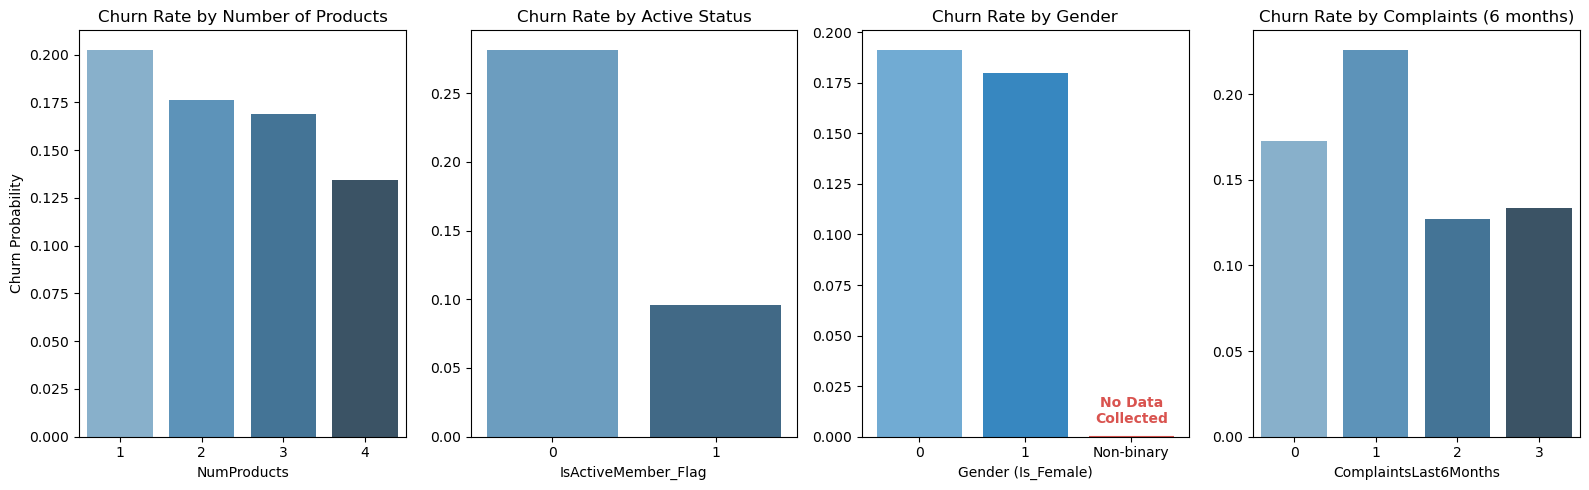

In [10]:
# NonBinry

# Bar Plots for Categorical Churn Rates
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

# Number of Products
sns.barplot(data=df_clean, x='NumProducts', y='Churn', errorbar=None, ax=axes[0], palette='Blues_d')
axes[0].set_title('Churn Rate by Number of Products')
axes[0].set_ylabel('Churn Probability')

# Active Status
sns.barplot(data=df_clean, x='IsActiveMember_Flag', y='Churn', errorbar=None, ax=axes[1], palette='Blues_d')
axes[1].set_title('Churn Rate by Active Status')
axes[1].set_ylabel('')

#  MODIFIED GENDER PLOT (Calculated directly from df_clean) ---
# Calculate exact churn rates from your dataset to ensure 100% accuracy
gender_means = df_clean.groupby('Is_Female')['Churn'].mean()

# Define labels and rates (0 = Male, 1 = Female, Adding 0.0 for missing Non-binary)
genders = ['0', '1', 'Non-binary']
rates = [gender_means.get(0, 0), gender_means.get(1, 0), 0.0]

# Draw the standard bars using your chosen Blues_d palette
bars = axes[2].bar(genders, rates, color=sns.color_palette("Blues_d", 3))

# Style the "Non-binary" bar (index 2) to explicitly show it is excluded/missing
bars[2].set_facecolor('#f8f9fa')  # Light gray background
bars[2].set_edgecolor('#d9534f')  # Red alert border
bars[2].set_hatch('//')           # Hatched pattern
bars[2].set_linewidth(1.5)

# Add explicit "No Data" annotation inside the empty bar
axes[2].text(x=2, y=0.005, s="No Data\nCollected", color='#d9534f', 
             ha="center", va="bottom", fontsize=10, fontweight='bold')

axes[2].set_title('Churn Rate by Gender')
axes[2].set_xlabel('Gender (Is_Female)')
axes[2].set_ylabel('')
# -------------------------------------------------------------------

# Complaints
sns.barplot(data=df_clean, x='ComplaintsLast6Months', y='Churn', errorbar=None, ax=axes[3], palette='Blues_d')
axes[3].set_title('Churn Rate by Complaints (6 months)')
axes[3].set_ylabel('')

plt.tight_layout()
# Save the plot as a high-resolution PNG
plt.savefig('Figures\EDA_BarPlots.png', dpi=300, bbox_inches='tight')
plt.show()